# 컨텍스트 로트(Context rot) 측정

**이 노트북에서 할 일**

1. 휴관 기록 하나를 목록 가운데에 두고, 무관한 기록 수만 10·100·1000개로 바꾼 입력 세 개를 만듭니다.
2. 세 입력을 한 번씩 보내고, 답의 지킬 말·출처 표시·토큰 수·예상 비용을 기록합니다.
3. 무관한 기록을 0개로 바꿔 한 번 더 보내고, 길이만 바뀐 비교인지 따져 봅니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 요청 기록은 셀 안에 담고, 파일은 만들지 않습니다.

인터넷 서비스에 요청을 모두 4번 보냅니다. 모두 `gpt-5.4-mini`입니다.

가장 긴 요청의 입력은 3만 토큰이 넘습니다. 01절 수업 예산 600을 일부러 넘기는 측정입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.03달러 안팎입니다. 요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**강의와 실습 범위** — 강의 시간에는 3·5·7절(측정 입력, 세 길이 요청, 요청 기록표)을 설명합니다.
4·6절(기록 함수, 값 바꿔 보기)은 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.8.0, tiktoken 0.14.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch08-context-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

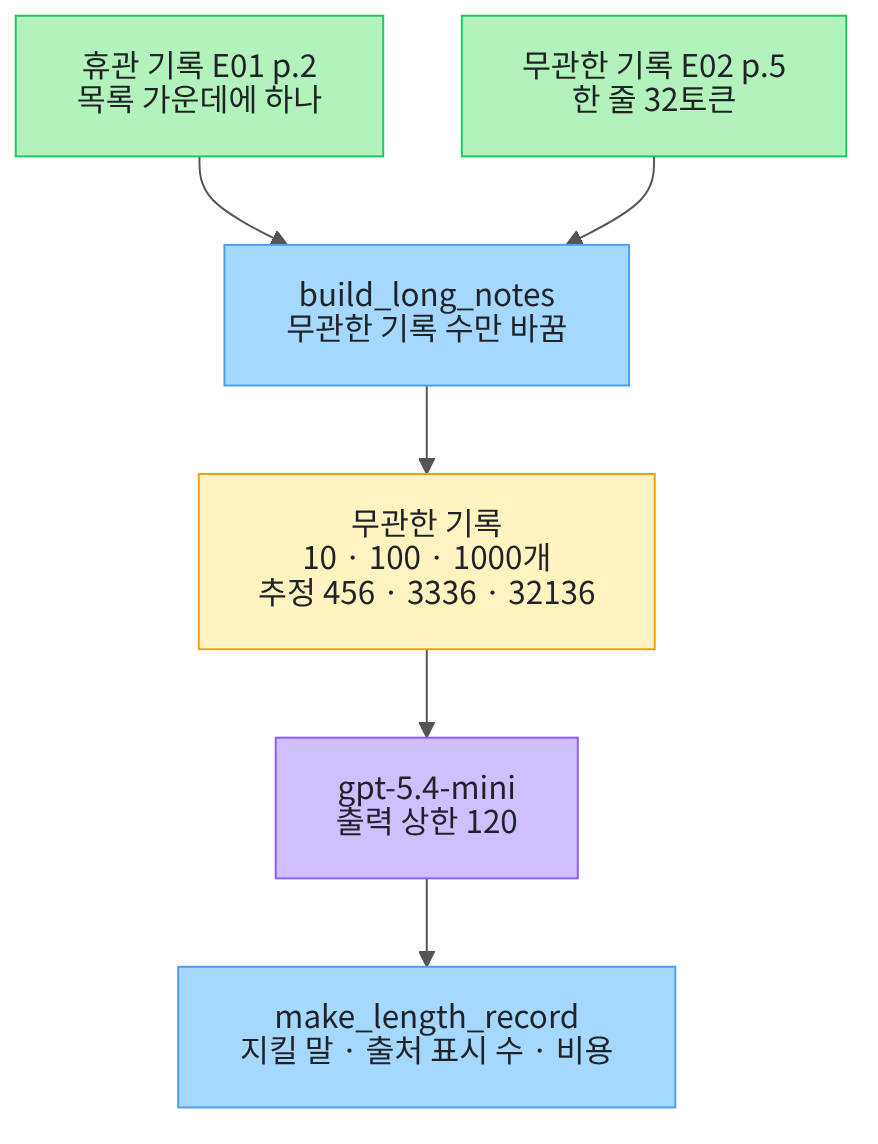

위에서 아래로 읽습니다. 맨 위 초록 상자 두 개는 넣을 기록입니다. 휴관 기록은 늘 하나이고, 무관한 기록만 개수가 바뀝니다.
파란 상자는 이 노트북에서 정의하는 함수이고, 노란 상자는 요청 전에 센 추정 입력입니다.

보라 상자 모델의 답은 마지막 파란 상자 함수로 요청 기록 한 줄이 됩니다. 답에서 무엇이 보였는지는 셀 출력으로 확인합니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01~04절과 같은 패키지 판을 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3" "tiktoken==0.14.0"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("tiktoken:", version("tiktoken"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.8.0
tiktoken: 0.14.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `openai: 3.8.0`, `tiktoken: 0.14.0` 등 여섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

토큰 수를 세는 라이브러리와 모델 함수를 불러오고, 앞에서 배운 함수 여섯 개를 가져옵니다. 이 절도 파일을 쓰지 않아 모듈 `json`·`tempfile`은 부르지 않습니다.

앞에서 배운 함수는 `llm_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 01절 `input_budget()`·`count_tokens()`, 03절 `find_missing_words()`, 04절 `build_notes_messages()`·`check_answer()`를 가져옵니다.
Ch 7 08절 `estimate_openai_cost()`도 가져옵니다.

도구 파일 판은 04절 판이 함수 바깥 이름에서 읽던 값을 인자로 받습니다. 함수 `build_notes_messages()`는 페르소나와 과업 명세를 앞의 두 인자로 받습니다.
함수 `check_answer()`는 지킬 말 목록을 셋째 인자로 받습니다.

In [2]:
# 토큰 수를 세는 라이브러리와 모델 함수를 불러옵니다
import tiktoken

from langchain.chat_models import init_chat_model
# 01·03·04절과 Ch 7 08절 함수 여섯 개를 도구 파일에서 가져옵니다
from llm_tools import build_notes_messages, check_answer, count_tokens, estimate_openai_cost, find_missing_words, input_budget

01~04절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


## 2. 04절에서 이어 쓰는 글과 함수

페르소나와 과업 명세는 02~04절과 글자까지 같습니다. 과업 명세는 문장마다 끝에 출처 표시를 적게 합니다.
출처 표시 `[E01 p.2]`는 모양을 보여 주는 예입니다.

In [4]:
# 02~04절과 같은 페르소나와 과업 명세를 만듭니다
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 출처를 [E01 p.2]처럼 적으세요."
print("페르소나:", persona_text)
print("과업 명세:", task_text)

페르소나: 당신은 미르시립도서관 안내 담당자입니다.
과업 명세: 주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 출처를 [E01 p.2]처럼 적으세요.


**결과 읽기** — 두 줄은 `페르소나:`와 `과업 명세:`로 시작합니다. 과업 명세 줄에 `문장마다 끝에 출처를`이 있습니다.

수업 예산표도 01~04절과 같은 값으로 이어 씁니다. 세 값을 담고, 준비 셀에서 가져온 01절 함수 `input_budget()`으로 입력 가용분을 구합니다.
실행 전에 예상합니다. 01~04절처럼 440일 것입니다.

In [5]:
# 01~04절과 같은 수업 예산·출력 예약분·여유분으로 입력 가용분을 계산합니다
total_budget = 600
output_reserve = 120
safety_margin = 40
available = input_budget(total_budget, output_reserve, safety_margin)
print("수업 예산:", total_budget)
print("출력 예약분:", output_reserve)
print("여유분:", safety_margin)
print("입력 가용분:", available)

수업 예산: 600
출력 예약분: 120
여유분: 40
입력 가용분: 440


**결과 읽기** — 네 줄은 `수업 예산: 600`, `출력 예약분: 120`, `여유분: 40`, `입력 가용분: 440`입니다.
이 절의 측정 입력은 이 입력 가용분을 일부러 넘깁니다. 까닭은 3절에서 설명합니다.

요청 전에 토큰 수를 세려고 01~04절처럼 토큰화 규칙 객체를 만듭니다. 가져온 함수 `count_tokens()`에 첫 인자로 넣을 객체입니다.

In [6]:
# 01~04절처럼 모델의 토큰화 규칙을 불러옵니다(가져온 count_tokens()에 첫 인자로 넣습니다)
encoding = tiktoken.encoding_for_model("gpt-5.4-mini")
print("토큰화 규칙 이름:", encoding.name)

토큰화 규칙 이름: o200k_base


**결과 읽기** — 출력 줄은 `토큰화 규칙 이름: o200k_base`로 01~04절과 같습니다.

모델 객체는 02~04절처럼 출력 예약분을 출력 상한(`max_tokens`)으로 주어 만듭니다. 이 셀은 요청을 보내지 않습니다.
입력이 길어져도 답에 줄 자리는 120토큰으로 같습니다.

In [7]:
# 출력 예약분을 출력 상한으로 준 모델을 준비합니다(02~04절과 같은 설정)
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    max_tokens=output_reserve,
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)
print("출력 상한(max_tokens):", model.max_tokens)
assert model.max_tokens == output_reserve

모델 이름: gpt-5.4-mini
temperature: 0.0
출력 상한(max_tokens): 120


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`, `temperature: 0.0`, `출력 상한(max_tokens): 120`입니다. `assert`도 통과했습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

휴관 기록·질문·지킬 말은 03·04절과 글자까지 같습니다. 휴관 기록은 E01 2쪽 원문을 읽고 지킬 말을 남기며 줄인 기록입니다.
이 절에서는 이 기록 하나가 모든 입력에 똑같이 들어갑니다.

In [8]:
# 03·04절과 같은 휴관 기록·질문·지킬 말을 만듭니다
closure_note = {
    "출처": "E01 p.2",
    "기관": "미르시립도서관",
    "주제": "휴관",
    "내용": "매주 월요일은 정기 휴관일이고 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다.",
}
closure_question = "미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?"
closure_keep_words = ["월요일", "법정 공휴일", "화요일"]
print("휴관 기록 출처:", closure_note["출처"])
print("질문:", closure_question)
print("지킬 말:", closure_keep_words)

휴관 기록 출처: E01 p.2
질문: 미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?
지킬 말: ['월요일', '법정 공휴일', '화요일']


**결과 읽기** — 출력 줄은 `휴관 기록 출처: E01 p.2`, `질문:` 줄, `지킬 말: ['월요일', '법정 공휴일', '화요일']`입니다.

준비 셀에서 가져온 세 함수로 목록을 만들고 답을 검사합니다. 03절 함수 `find_missing_words()`는 글 하나와 말 목록을 받아, 글에 없는 말만 목록으로 반환합니다.
04절 함수 `build_notes_messages()`는 기록 목록과 질문으로 Ch 7 모양의 메시지 목록을 만듭니다. 기록이 천 개여도 반복문이 한 줄씩 이어 붙입니다.

04절 함수 `check_answer()`는 답의 출처 표시와 같은 기록의 출처, 답에서 빠진 지킬 말을 딕셔너리로 반환합니다.
이 검사는 말이 있는지만 봅니다. 답의 품질 점수가 아닙니다.

## 3. 무관한 기록 수만 바꾼 입력 만들기

Ch 5 05절에서 컨텍스트 로트(context rot)라는 말을 배웠습니다. 입력이 길어질수록 필요한 정보를 찾아 쓰는 결과가 나빠지는 현상입니다.
04절의 산만은 긴 기록에 모델이 치우친 사례에 붙인 이름이라, 이 절이 재는 것과 다릅니다.

길이 때문인지 가르려면 길이 말고는 모두 같게 둡니다. 질문·휴관 기록·과업 명세·모델 설정은 모든 요청에서 같습니다.
휴관 기록은 늘 목록 가운데에 둡니다. 바꾸는 값은 휴관 기록 앞뒤에 넣는 무관한 기록의 수 하나입니다.

무관한 기록은 02절 기록 가운데 별빛제과 주차 기록을 씁니다. 휴관 질문과 관계없는 기록입니다.
실행 전에 예상합니다. 이 기록에는 휴관 지킬 말이 하나도 없을 것입니다.

In [9]:
# 휴관 질문과 관계없는 기록 하나를 만들고, 지킬 말이 들어 있는지와 한 줄의 토큰 수를 봅니다
filler_note = {"출처": "E02 p.5", "기관": "별빛제과", "주제": "주차", "내용": "본사 주차장은 선착순이며 월 3만 원의 주차비가 급여에서 공제됩니다."}
filler_line = "[" + filler_note["출처"] + "] " + filler_note["내용"] + "\n"
print("무관한 기록 출처:", filler_note["출처"])
print("무관한 기록에서 빠진 지킬 말:", find_missing_words(filler_note["내용"], closure_keep_words))
print("무관한 기록 한 줄 토큰 수:", count_tokens(encoding, filler_line))

무관한 기록 출처: E02 p.5
무관한 기록에서 빠진 지킬 말: ['월요일', '법정 공휴일', '화요일']
무관한 기록 한 줄 토큰 수: 32


**결과 읽기** — 출력 줄은 `무관한 기록 출처: E02 p.5`, `무관한 기록에서 빠진 지킬 말: ['월요일', '법정 공휴일', '화요일']`, `무관한 기록 한 줄 토큰 수: 32`입니다.
지킬 말 세 개가 모두 빠졌으므로, 이 기록에는 휴관 조건이 없습니다. 답에 지킬 말이 나오면 휴관 기록에서 온 말입니다.
한 줄 32토큰은 user 글에 들어가는 모양 그대로 센 값입니다.

Ch 5 05절 `make_document()` 함수는 무관한 문장 수와 근거 앞 문장 수를 받아 문서를 만들었습니다. 같은 생각으로 기록 목록을 만드는 함수를 정의합니다.
함수 `build_long_notes()`는 무관한 기록 수와 근거 앞 기록 수를 받습니다. 무관한 기록을 근거 앞 기록 수만큼 담고, 휴관 기록 하나와 나머지 무관한 기록을 담습니다.

함수 `range()`는 Ch 2에서 배운 대로 정한 횟수만큼 반복합니다. 반복 번호 `i`는 이 함수에서 쓰지 않습니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [10]:
# 무관한 기록 수와 근거 앞 기록 수를 받아, 휴관 기록 하나를 그 자리에 둔 기록 목록을 반환하는 함수를 정의합니다
def build_long_notes(filler_count, before_count):
    notes = []
    for i in range(before_count):
        notes.append(filler_note)
    notes.append(closure_note)
    after_count = filler_count - before_count
    for i in range(after_count):
        notes.append(filler_note)
    return notes

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

세 조건의 목록을 만듭니다. 근거 앞 기록 수를 무관한 기록 수의 절반으로 주어, 휴관 기록이 늘 가운데에 옵니다.
실행 전에 예상합니다. 기록 수는 휴관 기록 하나를 더해 11·101·1001개이고, 가운데 자리에는 휴관 기록이 있을 것입니다.

In [11]:
# 무관한 기록 10·100·1000개 조건의 목록을 만들고, 가운데 자리에 휴관 기록이 있는지 봅니다
notes_10 = build_long_notes(10, 5)
notes_100 = build_long_notes(100, 50)
notes_1000 = build_long_notes(1000, 500)
print("기록 수(10·100·1000개 조건):", len(notes_10), len(notes_100), len(notes_1000))
print("가운데 자리의 기록 출처:", notes_10[5]["출처"], notes_100[50]["출처"], notes_1000[500]["출처"])
assert notes_1000[500] == closure_note

기록 수(10·100·1000개 조건): 11 101 1001
가운데 자리의 기록 출처: E01 p.2 E01 p.2 E01 p.2


**결과 읽기** — 출력 줄은 `기록 수(10·100·1000개 조건): 11 101 1001`과 `가운데 자리의 기록 출처: E01 p.2 E01 p.2 E01 p.2`입니다. `assert`도 통과했습니다.
세 목록 모두 휴관 기록이 하나이고, 휴관 기록 앞뒤의 무관한 기록 수가 같습니다.

세 목록으로 메시지 목록을 만들고, 요청 전에 추정 입력을 셉니다. 페르소나와 과업 명세의 토큰 수는 세 목록이 같습니다.
실행 전에 예상합니다. 무관한 기록 한 줄이 32토큰이므로, 기록이 하나 늘 때마다 추정 입력도 32씩 늘 것입니다.

In [12]:
# 세 목록으로 메시지 목록을 만들고, 요청 전에 추정 입력을 셉니다(요청은 보내지 않습니다)
messages_10 = build_notes_messages(persona_text, task_text, notes_10, closure_question)
messages_100 = build_notes_messages(persona_text, task_text, notes_100, closure_question)
messages_1000 = build_notes_messages(persona_text, task_text, notes_1000, closure_question)
shared_tokens = count_tokens(encoding, persona_text) + count_tokens(encoding, task_text)
estimate_10 = shared_tokens + count_tokens(encoding, messages_10[2][1])
estimate_100 = shared_tokens + count_tokens(encoding, messages_100[2][1])
estimate_1000 = shared_tokens + count_tokens(encoding, messages_1000[2][1])
print("추정 입력 합계(10·100·1000개):", estimate_10, estimate_100, estimate_1000)
print("입력 가용분 안에 드는가:", estimate_10 <= available, estimate_100 <= available, estimate_1000 <= available)
print("가장 긴 user 글에서 빠진 지킬 말:", find_missing_words(messages_1000[2][1], closure_keep_words))

추정 입력 합계(10·100·1000개): 456 3336 32136
입력 가용분 안에 드는가: False False False
가장 긴 user 글에서 빠진 지킬 말: []


**결과 읽기** — 출력 줄은 `추정 입력 합계(10·100·1000개): 456 3336 32136`입니다. 그 아래 `입력 가용분 안에 드는가: False False False`가 나왔습니다.
마지막 줄 `가장 긴 user 글에서 빠진 지킬 말: []`은 1001줄 글 안에도 휴관 기록이 들어 있다는 확인입니다.
456에서 3336까지 기록 90개가 늘어 2880토큰이 늘었습니다. 한 줄에 32토큰씩으로 예상과 같습니다.

세 목록은 모두 01절 입력 가용분 440을 넘습니다. 수업 예산 600은 01절에서 흐름을 보여 주려고 정한 예산입니다.
보통 요청은 이 예산표로 입력을 먼저 줄입니다. 이 절은 긴 입력에서 답이 달라지는지 재려고 일부러 예산을 넘깁니다.

그래서 넘겨도 되는지는 두 가지로 따로 확인합니다. 하나는 01절에서 본 모델의 컨텍스트 윈도 400,000토큰입니다.
다른 하나는 비용입니다. 입력 요금은 입력 토큰 수에 비례하므로, 긴 요청 한 번이 짧은 요청 여러 번보다 비쌀 수 있습니다.

비용은 준비 셀에서 가져온 Ch 7 08절 함수 `estimate_openai_cost()`로 어림합니다. 사용량 딕셔너리를 받아 요청 한 번의 예상 비용(달러)을 반환합니다.
기본값은 Ch 6 06절에서 확인한 mini 요금입니다. 100만 토큰당 입력 0.75, 캐시 입력 0.075, 출력 4.50달러입니다.

요청 전에 컨텍스트 윈도와 비교하고, 세 목록의 예상 비용 상한을 어림합니다. 캐시 입력은 없고, 답이 출력 예약분 120토큰을 모두 쓴다고 봅니다.
사용량 대신 추정 입력과 출력 예약분으로 딕셔너리를 만들어 같은 함수에 넣습니다.
실행 전에 예상합니다. 가장 긴 목록 한 번이 합계의 대부분을 차지할 것입니다.

In [13]:
# 컨텍스트 윈도와 비교하고, 세 목록의 예상 비용 상한을 요청 전에 어림합니다(요청은 보내지 않습니다)
context_window = 400000
print("컨텍스트 윈도 안에 드는가:", estimate_1000 <= context_window)
planned_10 = estimate_openai_cost({"input_tokens": estimate_10, "output_tokens": output_reserve})
planned_100 = estimate_openai_cost({"input_tokens": estimate_100, "output_tokens": output_reserve})
planned_1000 = estimate_openai_cost({"input_tokens": estimate_1000, "output_tokens": output_reserve})
planned_total = planned_10 + planned_100 + planned_1000
print("예상 비용 상한(달러, 10·100·1000개):", round(planned_10, 6), round(planned_100, 6), round(planned_1000, 6))
print("세 요청 예상 비용 상한 합계(달러):", round(planned_total, 6))

컨텍스트 윈도 안에 드는가: True
예상 비용 상한(달러, 10·100·1000개): 0.000882 0.003042 0.024642
세 요청 예상 비용 상한 합계(달러): 0.028566


**결과 읽기** — 출력 줄은 `컨텍스트 윈도 안에 드는가: True`와 `예상 비용 상한(달러, 10·100·1000개): 0.000882 0.003042 0.024642`입니다.
마지막 줄은 `세 요청 예상 비용 상한 합계(달러): 0.028566`입니다. 가장 긴 목록 한 번이 합계의 대부분입니다.

가장 긴 목록도 컨텍스트 윈도의 10분의 1이 안 됩니다. 비용 상한 합계는 준비물에 적은 예상 비용 안입니다.
01절에서 본 것처럼 추정 입력은 실제보다 조금 적게 나오므로, 이 값은 여유분을 더하지 않은 어림입니다. 정확한 상한이 필요하면 추정 입력에 여유분 40을 더해 계산합니다.

무관한 기록을 한 번 더 10배 늘리면 추정 입력이 32만 토큰을 넘고, 비용 상한도 10배쯤 됩니다. 그래서 이 노트북은 1000개에서 멈춥니다.

## 4. 답을 기록할 함수

요청을 보내기 전에, 무엇이 보이면 「답이 나빠졌다」고 적을지 정합니다. 세 가지를 봅니다.

- 답에서 빠진 지킬 말: 빠진 말이 생기면 휴관 조건을 놓친 답입니다.
- 답의 출처 표시와 같은 기록: 휴관 기록 대신 무관한 기록 출처가 나오면 필요 없는 기록을 쓴 답입니다.
- 출처 표시 수: 과업 명세는 문장마다 출처를 적게 했습니다. 두 문장 답에 표시가 하나면 과업 명세를 덜 따른 답입니다.

세 항목 모두 말과 표시가 있는지만 봅니다. 답의 뜻은 답 원문을 읽어 확인합니다.

출처 표시 수를 세는 함수를 정의합니다. 메서드 `split()`에 표시 글을 주면, 답 글을 표시가 있던 자리마다 나눈 목록을 반환합니다.
나뉜 글의 수는 표시 수보다 하나 많으므로 1을 뺍니다. Ch 7 06절에서 줄을 나눌 때 쓴 메서드와 같습니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [14]:
# 답 글에 출처 표시가 몇 번 들어 있는지 세어 반환하는 함수를 정의합니다
def count_marks(answer_text, mark):
    pieces = answer_text.split(mark)
    mark_count = len(pieces) - 1
    return mark_count

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

요청 한 번의 결과를 요청 기록 한 줄로 만드는 함수를 정의합니다. 02절 기록(사실 한 문장)과 구분하려고, 이 딕셔너리는 요청 기록이라고 부릅니다. 함수 `check_answer()`가 반환한 딕셔너리에 키 다섯 개를 더합니다.
더하는 키는 `무관한 기록 수`, `실제 입력 토큰 수`, `캐시 입력 토큰 수`, `출처 표시 수`, `예상 비용(달러)`입니다.

캐시 입력 토큰 수는 Ch 6 06절에서 본 값입니다. 앞선 요청과 앞부분이 같은 입력은 일부가 캐시 입력 요금으로 계산될 수 있습니다.
답을 검사할 기록 목록에는 휴관 기록과 무관한 기록을 하나씩만 넣습니다. 같은 기록이 천 번 들어간 목록을 그대로 넣으면 같은 출처가 여러 번 나오기 때문입니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [15]:
# 무관한 기록 수와 응답 객체로, 답 검사·토큰 수·출처 표시 수·예상 비용을 담은 기록 한 줄을 반환하는 함수를 정의합니다
def make_length_record(filler_count, run_response):
    run_usage = run_response.usage_metadata
    record = check_answer(run_response.text, [closure_note, filler_note], closure_keep_words)
    closure_mark = "[" + closure_note["출처"] + "]"
    run_cost = estimate_openai_cost(run_usage)
    record["무관한 기록 수"] = filler_count
    record["실제 입력 토큰 수"] = run_usage["input_tokens"]
    record["캐시 입력 토큰 수"] = run_usage["input_token_details"]["cache_read"]
    record["출처 표시 수"] = count_marks(run_response.text, closure_mark)
    record["예상 비용(달러)"] = round(run_cost, 6)
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 5. 세 길이를 한 번씩 보내기

무관한 기록 10개 목록부터 보냅니다. 요청은 셀마다 하나씩, 세 셀로 나눠 보냅니다.
실행 전에 예상해 봅니다. 휴관 기록이 그대로 들어 있으니 지킬 말 세 개가 모두 답에 나올 것입니다.

In [16]:
# 무관한 기록 10개 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
response_10 = model.invoke(messages_10)
print("답:")
print(response_10.text)
print("끝난 이유:", response_10.response_metadata["finish_reason"])
print("실제 출력 토큰 수:", response_10.usage_metadata["output_tokens"])
record_10 = make_length_record(10, response_10)
print("기록:", record_10)

답:
미르시립도서관은 매주 월요일이 정기 휴관일이며 법정 공휴일에도 휴관합니다. 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다. [E01 p.2]
끝난 이유: stop
실제 출력 토큰 수: 58
기록: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': [], '무관한 기록 수': 10, '실제 입력 토큰 수': 470, '캐시 입력 토큰 수': 0, '출처 표시 수': 1, '예상 비용(달러)': 0.000614}


**결과 읽기** — 라벨 줄 아래 답은 두 문장입니다. 첫 문장은 `미르시립도서관은 매주 월요일이 정기 휴관일이며 법정 공휴일에도 휴관합니다.`입니다.
둘째 문장은 `공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다.`이고, 끝에만 `[E01 p.2]`가 붙었습니다.
그 아래 줄은 `끝난 이유: stop`과 `실제 출력 토큰 수: 58`입니다.

마지막 줄 요청 기록에서 `'답에서 빠진 지킬 말': []`, `'실제 입력 토큰 수': 470`, `'출처 표시 수': 1`을 봅니다.
지킬 말은 모두 남았습니다. 출처 표시는 둘째 문장 끝에 한 번이라, 문장마다 적으라는 과업 명세를 덜 따랐습니다.
무관한 기록의 출처 표시 「E02 p.5」는 답에 없습니다. 실행마다 답 문장이 달라질 수 있습니다.

무관한 기록 100개 목록을 보냅니다. 추정 입력은 10개 목록보다 7배쯤 깁니다.
실행 전에 예상해 봅니다. 입력이 길어져 답이 나빠진다면, 지킬 말이 빠지거나 출처 표시가 달라질 것입니다.

In [17]:
# 무관한 기록 100개 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
response_100 = model.invoke(messages_100)
print("답:")
print(response_100.text)
print("끝난 이유:", response_100.response_metadata["finish_reason"])
print("실제 출력 토큰 수:", response_100.usage_metadata["output_tokens"])
record_100 = make_length_record(100, response_100)
print("기록:", record_100)

답:
매주 월요일이 정기 휴관일이며 법정 공휴일에도 휴관합니다. 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다. [E01 p.2]
끝난 이유: stop
실제 출력 토큰 수: 50
기록: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': [], '무관한 기록 수': 100, '실제 입력 토큰 수': 3350, '캐시 입력 토큰 수': 2816, '출처 표시 수': 1, '예상 비용(달러)': 0.000837}


**결과 읽기** — 라벨 줄 아래 답은 `매주 월요일이 정기 휴관일이며`로 시작하는 두 문장이고, 끝에만 `[E01 p.2]`가 붙었습니다.
출력 줄은 `끝난 이유: stop`, `실제 출력 토큰 수: 50`입니다. 요청 기록에서 `'실제 입력 토큰 수': 3350`과 `'출처 표시 수': 1`을 봅니다.

10개 목록의 답과 견주면 첫머리 주어 「미르시립도서관은」만 빠졌고, 나머지 글자는 같습니다.
입력은 10개 목록보다 7배쯤 길었지만, 지킬 말과 출처 표시에서는 달라진 점을 찾지 못했습니다.
요청 기록의 `'캐시 입력 토큰 수': 2816`은 입력 앞부분 가운데 캐시 입력 요금으로 계산된 토큰 수입니다. 캐시 입력은 7절 표에서 함께 봅니다.

무관한 기록 1000개 목록을 보냅니다. 이 노트북에서 가장 긴 요청이고, 예상 비용도 가장 큽니다.
실행 전에 예상해 봅니다. 휴관 기록 앞에 무관한 기록이 500줄 있습니다. 길이 탓에 휴관 기록을 놓친다면 지킬 말이 빠질 것입니다.

In [18]:
# 무관한 기록 1000개 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
response_1000 = model.invoke(messages_1000)
print("답:")
print(response_1000.text)
print("끝난 이유:", response_1000.response_metadata["finish_reason"])
print("실제 출력 토큰 수:", response_1000.usage_metadata["output_tokens"])
record_1000 = make_length_record(1000, response_1000)
print("기록:", record_1000)

답:
미르시립도서관은 매주 월요일이 정기 휴관일이며 법정 공휴일에도 휴관합니다. 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다. [E01 p.2]
끝난 이유: stop
실제 출력 토큰 수: 58
기록: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': [], '무관한 기록 수': 1000, '실제 입력 토큰 수': 32150, '캐시 입력 토큰 수': 32000, '출처 표시 수': 1, '예상 비용(달러)': 0.002773}


**결과 읽기** — 라벨 줄 아래 답은 10개 목록의 답과 글자까지 같습니다. 출력 줄은 `끝난 이유: stop`, `실제 출력 토큰 수: 58`입니다.
요청 기록에서 `'답에서 빠진 지킬 말': []`, `'실제 입력 토큰 수': 32150`, `'출처 표시 수': 1`을 봅니다.
휴관 기록 앞에 무관한 기록이 500줄 있었지만, 이번 답은 지킬 말을 모두 담았습니다.

요청 기록의 `'캐시 입력 토큰 수': 32000`은 입력 대부분이 캐시 입력 요금으로 계산됐다는 뜻입니다.
그래서 `'예상 비용(달러)': 0.002773`이 요청 전 어림 0.024642보다 훨씬 작습니다.

교재 출력 바로 앞의 새 커널 실행에서 같은 목록을 보냈습니다. 그 실행의 이 요청은 캐시 입력이 0이었고, 예상 비용은 0.024338달러로 요청 전 어림에 가까웠습니다.
캐시 입력은 앞선 요청에 따라 실행마다 달라집니다. 처음 보내는 입력이면 비용은 요청 전 어림에 가깝다고 보고 준비합니다.

## 6. 값 바꿔 보기 — 무관한 기록 0개

바꾸는 값은 무관한 기록 수 하나입니다. 10개를 0개로 줄여, 휴관 기록 하나만 든 목록을 만듭니다.
이 목록은 04절 기준 목록과 같은 모양입니다. 추정 입력은 가장 짧고, 수업 예산 안에 듭니다.

실행 전에 예상합니다. 길이만 줄었다고 보면, 답은 10개 목록의 답과 같은 모양일 것입니다.

In [19]:
# 무관한 기록 0개 목록을 만들고 추정 입력을 셉니다(요청은 보내지 않습니다)
notes_0 = build_long_notes(0, 0)
messages_0 = build_notes_messages(persona_text, task_text, notes_0, closure_question)
estimate_0 = shared_tokens + count_tokens(encoding, messages_0[2][1])
print("기록 수:", len(notes_0))
print("추정 입력 합계:", estimate_0)
print("입력 가용분 안에 드는가:", estimate_0 <= available)
assert notes_0 == [closure_note]

기록 수: 1
추정 입력 합계: 136
입력 가용분 안에 드는가: True


**결과 읽기** — 출력 줄은 `기록 수: 1`, `추정 입력 합계: 136`, `입력 가용분 안에 드는가: True`입니다. `assert`도 통과했습니다.
추정 136은 04절 기준 목록과 같은 값입니다.

무관한 기록 0개 목록을 보냅니다. 앞의 세 요청과 같은 함수로 요청 기록 한 줄을 만듭니다.

In [20]:
# 무관한 기록 0개 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
response_0 = model.invoke(messages_0)
print("답:")
print(response_0.text)
print("끝난 이유:", response_0.response_metadata["finish_reason"])
print("실제 출력 토큰 수:", response_0.usage_metadata["output_tokens"])
record_0 = make_length_record(0, response_0)
print("기록:", record_0)

답:
미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다. [E01 p.2] 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다. [E01 p.2]
끝난 이유: stop
실제 출력 토큰 수: 66
기록: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': [], '무관한 기록 수': 0, '실제 입력 토큰 수': 150, '캐시 입력 토큰 수': 0, '출처 표시 수': 2, '예상 비용(달러)': 0.000409}


**결과 읽기** — 라벨 줄 아래 답은 두 문장이고, 두 문장 끝에 모두 `[E01 p.2]`가 붙었습니다. 첫 문장은 `미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다.`입니다.
요청 기록에서 `'실제 입력 토큰 수': 150`, `'출처 표시 수': 2`, `'답에서 빠진 지킬 말': []`을 봅니다.

예상과 달리 출처 표시 수가 10개 목록의 1과 달랐습니다. 지킬 말은 두 답 모두 빠지지 않았습니다.
0개 목록과 10개 목록은 길이만 다른 것이 아닙니다. 0개 목록에는 무관한 기록이 아예 없습니다.
그래서 이 차이가 길이 때문인지, 무관한 기록이 있어서인지 이 비교로는 가를 수 없습니다.

## 7. 요청 기록표로 비교하기

네 요청 기록을 무관한 기록 수 순서로 모아 한 표로 출력합니다. 한 줄에 요청 하나입니다.
반복문은 이미 받은 요청 기록을 출력만 하고, 요청을 보내지 않습니다. 마지막 줄은 네 요청의 예상 비용 합계입니다.

In [21]:
# 네 기록을 무관한 기록 수 순서로 모아 한 줄에 한 요청씩 출력합니다
length_records = [record_0, record_10, record_100, record_1000]
total_cost = 0
print("기록표(무관한 기록 수 | 실제 입력 토큰 수 | 캐시 입력 토큰 수 | 출처 표시 수 | 답의 출처 표시와 같은 기록 | 답에서 빠진 지킬 말 | 예상 비용(달러)):")
for record in length_records:
    total_cost = total_cost + record["예상 비용(달러)"]
    print(record["무관한 기록 수"], "|", record["실제 입력 토큰 수"], "|", record["캐시 입력 토큰 수"], "|", record["출처 표시 수"], "|", record["답의 출처 표시와 같은 기록"], "|", record["답에서 빠진 지킬 말"], "|", record["예상 비용(달러)"])
print("네 요청 예상 비용 합계(달러):", round(total_cost, 6))

기록표(무관한 기록 수 | 실제 입력 토큰 수 | 캐시 입력 토큰 수 | 출처 표시 수 | 답의 출처 표시와 같은 기록 | 답에서 빠진 지킬 말 | 예상 비용(달러)):
0 | 150 | 0 | 2 | ['E01 p.2'] | [] | 0.000409
10 | 470 | 0 | 1 | ['E01 p.2'] | [] | 0.000614
100 | 3350 | 2816 | 1 | ['E01 p.2'] | [] | 0.000837
1000 | 32150 | 32000 | 1 | ['E01 p.2'] | [] | 0.002773
네 요청 예상 비용 합계(달러): 0.004633


**결과 읽기** — 라벨 줄 아래 네 줄은 `0 | 150 | 0 | 2 | ['E01 p.2'] | [] | 0.000409`부터 `1000 | 32150 | 32000 | 1 | ['E01 p.2'] | [] | 0.002773`까지입니다.
마지막 줄은 `네 요청 예상 비용 합계(달러): 0.004633`입니다.

무관한 기록 10·100·1000개 세 줄은 출처 표시 수 1, 빠진 지킬 말 없음으로 같았습니다. 실제 입력 토큰 수만 470에서 32150으로 늘었습니다.
네 줄 모두 답의 출처 표시와 같은 기록은 휴관 기록 하나였습니다. 출처 표시 수가 2인 줄은 0개 목록 하나뿐입니다.

## 실험 결과 해석

무관한 기록을 10개에서 1000개로 늘려 입력이 470토큰에서 32150토큰으로 길어졌습니다. 세 답은 첫머리 주어 「미르시립도서관은」이 있고 없는 것만 달랐고, 지킬 말과 출처 표시 수는 같았습니다.
이번 세 요청에서는 입력 길이에 따라 답이 나빠진 모습을 보지 못했습니다.

값 바꿔 보기에서 무관한 기록을 0개로 줄이자 출처 표시 수가 2로 달라졌습니다.
이 비교는 길이와 함께 무관한 기록이 있는지도 바뀌어, 컨텍스트 로트를 잰 결과로 쓰지 않습니다. 왜 달라졌는지도 이번 실행으로 알 수 없습니다.

이 결론은 모델 하나, 질문 하나, 길이 세 가지를 한 번씩 보낸 범위입니다. 같은 기록을 되풀이한 연습용 입력이고, 휴관 기록은 늘 가운데에 있었습니다.
Ch 5 05절은 내 컴퓨터의 작은 모델로 근거 자리를 바꿔 봤고, 이 절은 서비스 모델로 길이만 바꿨습니다. 조건이 달라 두 결과를 한 규칙으로 묶지 않습니다.

## 정리

- 휴관 기록을 가운데에 두고 무관한 기록만 10·100·1000개로 늘렸습니다. 입력이 470~32150토큰으로 길어져도 세 답의 지킬 말과 출처 표시 수는 같았습니다.
- 측정 입력은 수업 예산을 일부러 넘겼으므로, 컨텍스트 윈도와 예상 비용을 요청 전에 따로 확인했습니다. 캐시 입력이 생기면 실제 비용은 어림보다 작아졌습니다.
- 무관한 기록 0개 답만 출처 표시가 2번이었습니다. 길이와 기록 유무가 함께 바뀐 비교라 길이 탓으로 보지 않습니다.

다음 06절에서는 필요한 문서의 본문만 골라 여는 단계적 공개를 배우고, 입력 설계 몇 가지를 같은 질문으로 비교합니다.